# Assignment Part B: Quantum Computing

**Roll Number:** 2025BCY0004

**Course:** Quantum Computing and Post-Quantum Cryptography

## Objectives

1. To construct and verify all four Bell states using quantum circuits.
2. To design a personalized 12-qubit quantum circuit using roll-number encoding.
3. To understand the Learning With Errors (LWE) problem and its role in post-quantum cryptography.


In [10]:
%pip install qiskit qiskit-aer matplotlib numpy
%pip install pylatexenc

## Task 1: Construction of All Four Bell States

### Aim

To construct all four Bell states using quantum gates and verify their properties using statevectors and measurement histograms.

### Theory

Bell states are two-qubit quantum states that exhibit entanglement. Entangled qubits have correlations that cannot be explained by treating them as independent quantum systems.

The four Bell states are:

1. **Phi Plus:** \(|\Phi^+\rangle = (|00\rangle + |11\rangle)/\sqrt{2}\)
2. **Phi Minus:** \(|\Phi^-\rangle = (|00\rangle - |11\rangle)/\sqrt{2}\)
3. **Psi Plus:** \(|\Psi^+\rangle = (|01\rangle + |10\rangle)/\sqrt{2}\)
4. **Psi Minus:** \(|\Psi^-\rangle = (|01\rangle - |10\rangle)/\sqrt{2}\)

The Hadamard gate creates superposition, the CNOT gate creates entanglement, the Pauli-X gate flips a qubit, and the Pauli-Z gate changes its phase.

### Procedure

A two-qubit circuit is initialized in the state \(|00\rangle\). A Hadamard gate is applied to the first qubit, followed by a CNOT gate. Additional Pauli gates are used to construct the remaining Bell states.


In [11]:
import numpy as np
import matplotlib.pyplot as plt

from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

print("Libraries imported successfully!")

Libraries imported successfully!


### Circuit Construction

A common circuit is used to generate the four Bell states. First, the Hadamard gate places the control qubit into superposition. Next, the CNOT gate entangles the two qubits.

The remaining Bell states are obtained by applying appropriate Pauli-X and Pauli-Z operations. Each circuit is displayed to show the sequence of quantum gates used to prepare the corresponding state.



Bell State: Phi+


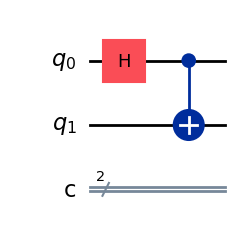

Statevector:
Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))

Bell State: Phi-


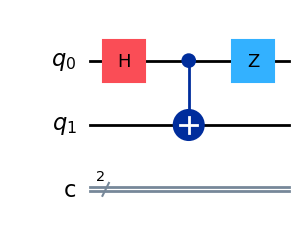

Statevector:
Statevector([ 0.70710678+0.j,  0.        +0.j,  0.        +0.j,
             -0.70710678+0.j],
            dims=(2, 2))

Bell State: Psi+


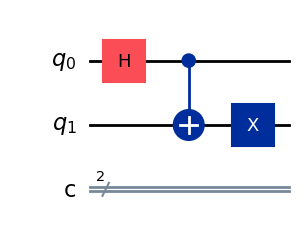

Statevector:
Statevector([0.        +0.j, 0.70710678+0.j, 0.70710678+0.j,
             0.        +0.j],
            dims=(2, 2))

Bell State: Psi-


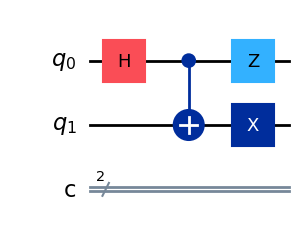

Statevector:
Statevector([ 0.        +0.j, -0.70710678+0.j,  0.70710678+0.j,
              0.        +0.j],
            dims=(2, 2))


In [12]:
# Assignment Part B - Task 1
# Roll Number: 2025BCY0004

def create_bell_state(name):

    qc = QuantumCircuit(2, 2)

    # Step 1: Create superposition
    qc.h(0)

    # Step 2: Create entanglement
    qc.cx(0, 1)

    # Step 3: Modify the state to obtain the required Bell state

    if name == "Phi+":
        pass

    elif name == "Phi-":
        qc.z(0)

    elif name == "Psi+":
        qc.x(1)

    elif name == "Psi-":
        qc.x(1)
        qc.z(0)

    return qc


# Create the four Bell states
bell_states = ["Phi+", "Phi-", "Psi+", "Psi-"]

for name in bell_states:

    qc = create_bell_state(name)

    print("\nBell State:", name)

    # Display the circuit
    display(qc.draw("mpl"))

    # Obtain the statevector before measurement
    state_circuit = qc.remove_final_measurements(
        inplace=False
    )

    sv = Statevector.from_instruction(state_circuit)

    print("Statevector:")
    print(sv)

### Measurement and Verification

The circuits are simulated using the Qiskit Aer simulator. Each circuit is measured over multiple shots, and the resulting measurement counts are displayed as histograms.

The Phi states are expected to produce correlated outcomes, 00 and 11. The Psi states are expected to produce anticorrelated outcomes, 01 and 10.

The statevector is also examined because the measurement histograms in the computational basis cannot distinguish the relative phases of the plus and minus Bell states.



Measurement results for Phi+
{'11': 1008, '00': 1040}


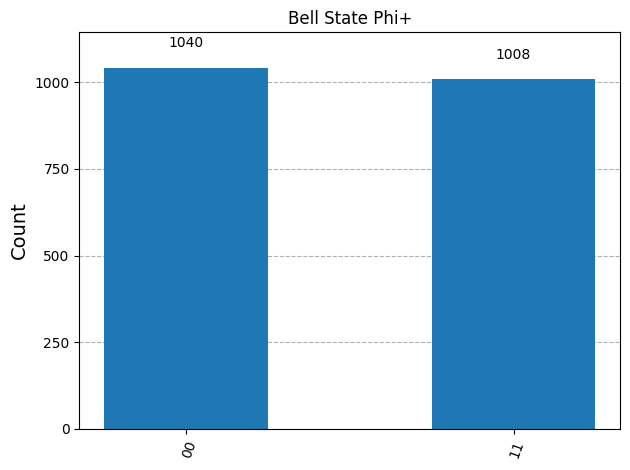


Measurement results for Phi-
{'11': 996, '00': 1052}


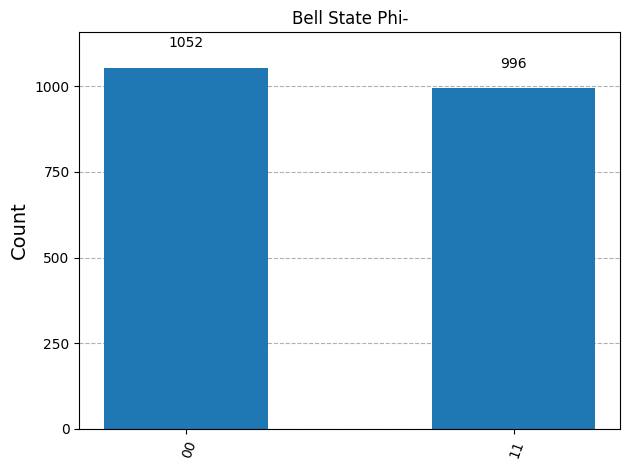


Measurement results for Psi+
{'10': 1043, '01': 1005}


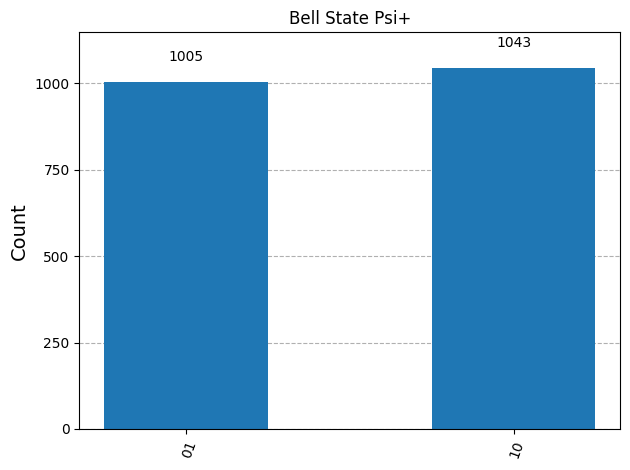


Measurement results for Psi-
{'10': 982, '01': 1066}


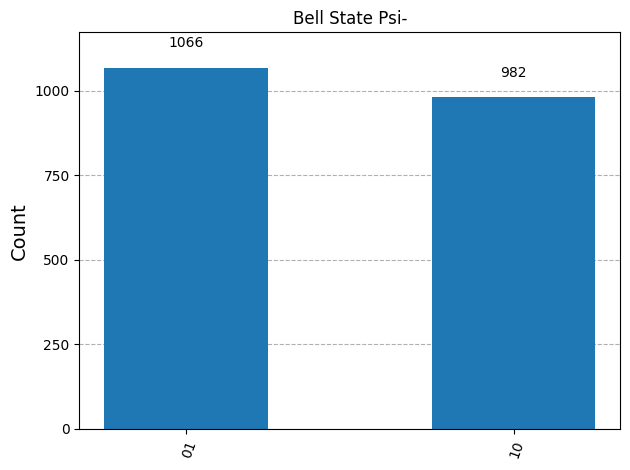

In [13]:
# Simulate measurements of all four Bell states

simulator = AerSimulator()

for name in bell_states:

    qc = create_bell_state(name)

    # Measure both qubits
    qc.measure(0, 0)
    qc.measure(1, 1)

    # Compile and simulate
    compiled = transpile(qc, simulator)

    result = simulator.run(
        compiled,
        shots=2048
    ).result()

    counts = result.get_counts()

    print("\nMeasurement results for", name)
    print(counts)

    display(
        plot_histogram(
            counts,
            title="Bell State " + name
        )
    )

### Results and Observations

All four Bell states were constructed using Hadamard, CNOT, Pauli-X, and Pauli-Z gates. The statevectors showed the expected amplitudes and relative phases for each state.

The measurement histograms showed correlated outcomes for the Phi states and anticorrelated outcomes for the Psi states. The results demonstrate how quantum gates can create and modify entangled states.

### Conclusion

The experiment successfully demonstrated the construction and verification of all four Bell states. Statevector analysis and measurement histograms provided complementary methods for examining their quantum properties.


In [14]:
# Assignment Part B - Task 2
# Roll Number: 2025BCY0004

roll_number = "2025BCY0004"

year = int(roll_number[:4])

last_four = int(roll_number[-4:])

number = year + last_four

binary_string = format(number, "012b")[-12:]

print("Roll Number:", roll_number)
print("Year:", year)
print("Last four digits:", last_four)
print("Calculated number:", number)
print("12-bit binary string:", binary_string)
print("Number of bits:", len(binary_string))

Roll Number: 2025BCY0004
Year: 2025
Last four digits: 4
Calculated number: 2029
12-bit binary string: 011111101101
Number of bits: 12


## Task 2: Personalized Quantum Circuit Using Roll-Number Encoding

### Aim

To design a 12-qubit quantum circuit using a binary representation derived from my roll number, apply the specified quantum gates, and analyze the measurement results.

### Roll-Number Processing

My roll number is **2025BCY0004**.

The last four digits are 0004, which represents the number 4. Adding this number to the year gives:

2025 + 4 = 2029

The decimal number 2029 is converted into binary. Its binary representation is 11111101101. A leading zero is added to obtain the required 12-bit string:

**011111101101**

Each bit represents the initial computational-basis state of one qubit, where 0 corresponds to \(|0\rangle\) and 1 corresponds to \(|1\rangle\).


12-Qubit Personalized Quantum Circuit


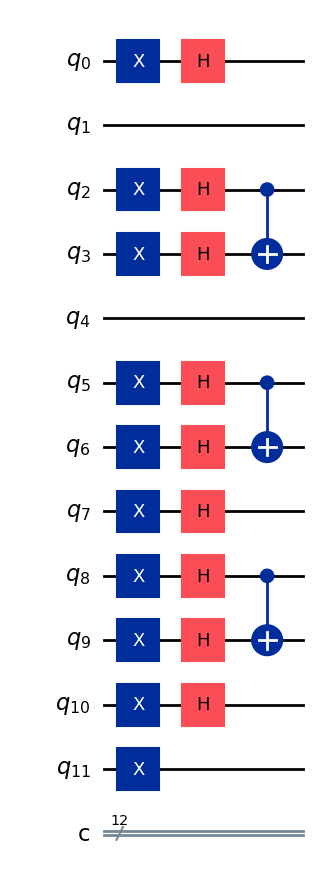

In [15]:
# Create a 12-qubit circuit

n = 12

qc = QuantumCircuit(n, n)

# Step 1: Initialize qubits using the binary string
# The rightmost bit maps to Qiskit's qubit 0.

for i, bit in enumerate(reversed(binary_string)):

    if bit == "1":
        qc.x(i)

# Step 2: Apply Hadamard gates to qubits
# that were initialized to |1>

for i, bit in enumerate(reversed(binary_string)):

    if bit == "1":
        qc.h(i)

# Step 3: Apply CNOT gates
# Assignment qubits: 3 -> 4, 6 -> 7, 9 -> 10

qc.cx(2, 3)
qc.cx(5, 6)
qc.cx(8, 9)

# Step 4: Apply the final gate
# Last digit of roll number = 4, which is even
# Therefore, apply X to the last qubit.

last_digit = int(roll_number[-1])

if last_digit % 2 == 0:
    qc.x(11)
else:
    qc.z(11)

# Step 5: Display the circuit

print("12-Qubit Personalized Quantum Circuit")

display(qc.draw("mpl"))

### Quantum Circuit Design

A quantum circuit containing 12 qubits is created using Qiskit. The binary string is encoded into the qubits by applying X gates wherever a bit is 1.

Hadamard gates are then applied to the qubits that were initially set to \(|1\rangle\), creating superposition. CNOT gates connect the third qubit to the fourth, the sixth qubit to the seventh, and the ninth qubit to the tenth.

Since the last digit of my roll number is 4, which is even, an X gate is applied to the twelfth qubit. The resulting circuit diagram is displayed for verification.

**Note:** Qiskit uses zero-based qubit indexing. The specified connections therefore correspond to Qiskit indices 2 → 3, 5 → 6, and 8 → 9. A connection from qubit 12 to qubit 13 is omitted because the circuit contains only 12 qubits.


In [16]:
# Calculate the statevector before measurement

sv = Statevector.from_instruction(qc)

print("Statevector verification:")

print(sv)

print("\nNonzero amplitudes:")

for i, amplitude in enumerate(sv.data):

    if abs(amplitude) > 1e-9:

        state = format(i, "012b")

        print(state, ":", np.round(amplitude, 4))

Statevector verification:
Statevector([0.+0.j, 0.+0.j, 0.+0.j, ..., 0.+0.j, 0.+0.j, 0.+0.j],
            dims=(2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2))

Nonzero amplitudes:
100000000000 : (0.0442+0j)
100000000001 : (-0.0442+0j)
100000000100 : (0.0442+0j)
100000000101 : (-0.0442+0j)
100000001000 : (-0.0442+0j)
100000001001 : (0.0442+0j)
100000001100 : (-0.0442+0j)
100000001101 : (0.0442+0j)
100000100000 : (0.0442+0j)
100000100001 : (-0.0442+0j)
100000100100 : (0.0442+0j)
100000100101 : (-0.0442+0j)
100000101000 : (-0.0442+0j)
100000101001 : (0.0442+0j)
100000101100 : (-0.0442+0j)
100000101101 : (0.0442+0j)
100001000000 : (-0.0442+0j)
100001000001 : (0.0442+0j)
100001000100 : (-0.0442+0j)
100001000101 : (0.0442+0j)
100001001000 : (0.0442+0j)
100001001001 : (-0.0442+0j)
100001001100 : (0.0442+0j)
100001001101 : (-0.0442+0j)
100001100000 : (-0.0442+0j)
100001100001 : (0.0442+0j)
100001100100 : (-0.0442+0j)
100001100101 : (0.0442+0j)
100001101000 : (0.0442+0j)
100001101001 : (-0.0442+0j)
100001

### Statevector Analysis

The statevector represents the quantum state of the entire 12-qubit system before measurement. A 12-qubit system has \(2^{12} = 4096\) computational-basis amplitudes.

Only basis states with nonzero amplitudes contribute to the prepared state. Examining these amplitudes helps identify the possible outcomes and their associated probability amplitudes.


Measured Quantum Circuit:


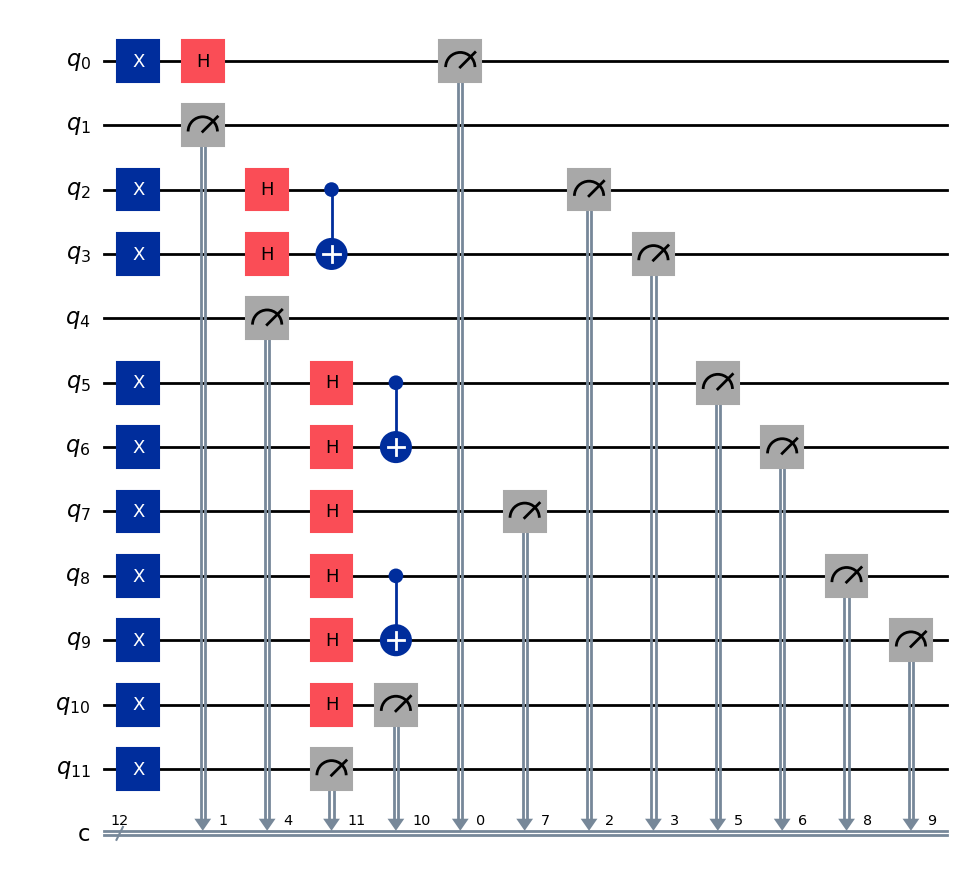

Measurement results:
{'111101101000': 3, '100110100101': 1, '101111101100': 1, '100011100001': 2, '100011001101': 4, '101100100000': 1, '100010001101': 2, '101001001100': 6, '100001101001': 1, '100101000000': 2, '111000001001': 4, '111111100000': 1, '100000000000': 2, '110110100101': 2, '110001000000': 4, '110001001001': 3, '100011101001': 2, '101100101101': 1, '111110100100': 1, '101110100101': 1, '101100000001': 1, '101101100100': 2, '111100100001': 1, '111011001100': 6, '110111001000': 1, '111000101100': 2, '100110000101': 4, '110010000101': 3, '101101000001': 6, '111011000000': 2, '101111001000': 4, '110011100101': 3, '100100000100': 4, '101010100000': 4, '110001100100': 4, '100011101101': 2, '110101100000': 4, '101000101100': 5, '110010101000': 3, '100100100001': 5, '100111101101': 6, '100101100001': 2, '101001101100': 4, '100111001000': 3, '111111000000': 7, '100111100001': 5, '101001100101': 5, '110000000100': 2, '110101001000': 4, '101010101101': 4, '110100101001': 4, '10111110

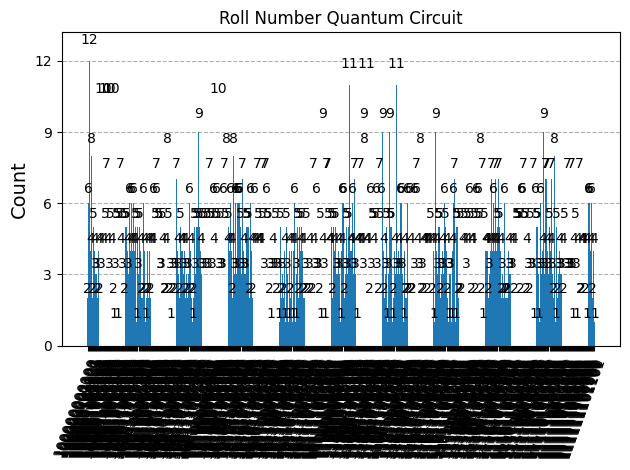

In [17]:
# Copy the circuit and add measurements

qc_measure = qc.copy()

qc_measure.measure(
    range(12),
    range(12)
)

print("Measured Quantum Circuit:")

display(qc_measure.draw("mpl"))

# Simulate the measurements

simulator = AerSimulator()

compiled = transpile(
    qc_measure,
    simulator
)

result = simulator.run(
    compiled,
    shots=2048
).result()

counts = result.get_counts()

print("Measurement results:")

print(counts)

display(
    plot_histogram(
        counts,
        title="Roll Number Quantum Circuit"
    )
)

### Measurement and Visualization

All 12 qubits are measured using the Qiskit Aer simulator. The circuit is executed for 2048 shots to obtain measurement counts.

A histogram is generated to visualize the observed frequencies of the possible bit-string outcomes. The results reflect the superposition introduced by the Hadamard gates and the conditional relationships created by the CNOT gates.


In [18]:
# Assignment Part B - Task 3
# Learning With Errors (LWE)
# Roll Number: 2025BCY0004

import random

# Step 1: Define the roll number

roll_number = "2025BCY0004"

# Step 2: Define the modulus

q = 97

print("STEP 1: Public parameter")
print("Modulus q =", q)

# Step 3: Generate the secret using the last three digits

s = int(roll_number[-3:]) % q

print("\nSTEP 2: Secret key")
print("Last three digits =", roll_number[-3:])
print("Secret key s =", s)

# Step 4: Randomly choose a public value A

A = random.randint(1, q - 1)

print("\nSTEP 3: Public value")
print("A =", A)

# Step 5: Generate a small random error

e = random.randint(-2, 2)

print("\nSTEP 4: Error value")
print("e =", e)

# Step 6: Randomly select the message bit

message = random.randint(0, 1)

print("\nSTEP 5: Random message")
print("Message bit =", message)

# Step 7: Calculate B

print("\nSTEP 6: Calculate B")

print("Formula: B = (A * s + e) mod q")

raw_value = A * s + e

B = raw_value % q

print("A * s =", A * s)

print("A * s + e =", raw_value)

print("B =", raw_value, "mod", q, "=", B)

# Step 8: Display the summary

print("\nFINAL SUMMARY")

print("A =", A)
print("B =", B)
print("e =", e)
print("s =", s)
print("q =", q)
print("Message =", message)

STEP 1: Public parameter
Modulus q = 97

STEP 2: Secret key
Last three digits = 004
Secret key s = 4

STEP 3: Public value
A = 55

STEP 4: Error value
e = -1

STEP 5: Random message
Message bit = 0

STEP 6: Calculate B
Formula: B = (A * s + e) mod q
A * s = 220
A * s + e = 219
B = 219 mod 97 = 25

FINAL SUMMARY
A = 55
B = 25
e = -1
s = 4
q = 97
Message = 0
